# Reproduce this SPHEREx view: images → checks → blink → evidence

Download this notebook and **notebook-example.zip**, extract the ZIP beside it, and run all cells. Python3.10+, NumPy2.0+, matplotlib, Pillow and Jupyter are required. The bundled real example runs offline. No installation, remote request or native fitting runs by default.

The offline example contains prepared **analysis previews** (IMAGE minus ZODI, quality masked, sky aligned/common stretch). It differs from the viewer's default archive IMAGE display. No motion, variability, source detection or calibrated brightness is established by this notebook.

For another field: configure the server URL, RA/Dec and diameter; explicitly enable metadata access; inspect available dates/wavelength semantics; select at most4observationIDs; explicitly enable cutout preparation. The server handles native WCS alignment and common stretching. This notebook does not independently reproject FITS or subtract PNGs for scientific photometry.

In [1]:
from pathlib import Path
import json,io,time,hashlib,re,urllib.request,urllib.parse
import numpy as np
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as NotebookImage

RUN_LIVE=False             # explicitly enable server metadata/image access
PREPARE=False              # explicitly request new cutout preparation
SERVER='http://127.0.0.1:8765' # replace with your deployed server URL
VIEW_URL=''                # optional copied viewer URL with job and exact view state
RA,DEC=133.7951291667,-7.2451472222
FOV_ARCMIN=5
OBSERVATION_IDS=[]          # inspect metadata, then choose at most4 IDs
SOURCE='analysis'          # analysis or archive; offline example is analysis
INTENT='colour'            # time requires comparable, distinct-epoch frames
POLL_SECONDS=120
MAX_FRAMES=4
MAX_IMAGE_BYTES=2*1024*1024
TOTAL_IMAGE_BUDGET=8*1024*1024
SAMPLE=Path('notebook-example')
OUTPUT=Path('spherex-reproduction')
OUTPUT.mkdir(exist_ok=True)

parts=urllib.parse.urlsplit(SERVER)
assert parts.scheme in ('http','https') and parts.netloc and not parts.username and not parts.password
ORIGIN=parts.scheme+'://'+parts.netloc
def fetch_bytes(path,maximum=MAX_IMAGE_BYTES):
    assert path.startswith('/') and not path.startswith('//') and '..' not in path.split('/'), 'Server-relative path required.'
    request=urllib.request.Request(ORIGIN+path,headers={'Origin':ORIGIN})
    with urllib.request.urlopen(request,timeout=30) as h:
        assert urllib.parse.urlsplit(h.url).netloc==parts.netloc,'Cross-host redirect rejected.'
        value=h.read(maximum+1)
    assert len(value)<=maximum,'Download exceeded its explicit limit.'
    return value
def api(path): return json.loads(fetch_bytes(path,8*1024*1024))
saved_view=None;job_id=None
if VIEW_URL:
    assert RUN_LIVE, 'Enable RUN_LIVE to reproduce a server view; offline example data cannot replace it.'
    q=urllib.parse.parse_qs(urllib.parse.urlsplit(VIEW_URL).query)
    assert urllib.parse.urlsplit(VIEW_URL).netloc==parts.netloc, 'Set SERVER to the same host as VIEW_URL.'
    RA=float(q.get('ra',[RA])[0]); DEC=float(q.get('dec',[DEC])[0]); FOV_ARCMIN=float(q.get('fov',[FOV_ARCMIN])[0])
    job_id=q.get('job',[None])[0]
    assert not q.get('view') or len(q['view'][0])<=20000, 'Saved view is too large.'
    saved_view=json.loads(q['view'][0]) if q.get('view') else None
    if saved_view:
        assert saved_view.get('v')==1 and len(saved_view.get('frames',[]))<=MAX_FRAMES,'Choose a saved view with at most4frames.'
        assert saved_view['source'] in ('raw','processed') and saved_view['intent'] in ('time','colour'), 'Unsupported saved viewing mode.'
        assert isinstance(saved_view['frames'],list) and len(set(saved_view['frames']))==len(saved_view['frames']), 'Invalid saved frame list.'
        SOURCE='archive' if saved_view['source']=='raw' else 'analysis'
        INTENT=saved_view['intent']
print('Live access:',RUN_LIVE,'New preparation:',PREPARE,'Output:',OUTPUT.resolve())

Live access: False New preparation: False Output: C:\Users\rvall\Documents\Codex\2026-11-14\spherex-space-apps\outputs\spherex-viewer\web\spherex-reproduction


## 1. Discover observations without downloading science pixels

Set RUN_LIVE=True to query your server. Footprint overlap is not detection. The returned coverage/freshness information must stay with the report. Metadata detector bounds are not the exact wavelength at your target. Fixed target coordinates are not a propagated stellar track.

In [2]:
metadata=None
if RUN_LIVE:
    assert 0<=RA<360 and -90<=DEC<=90 and 1<=FOV_ARCMIN<=60
    query=urllib.parse.urlencode(dict(ra=RA,dec=DEC,fov_arcmin=FOV_ARCMIN,mode='cache_only',limit=100))
    metadata=api('/api/v1/observations?'+query)
    print('Coverage:',metadata['coverage'])
    for row in metadata['observations'][:20]:
        print(row['id'],row['time_start_utc'],row['detector'],row['wavelength_semantics'])
    print('More records may exist; use the API cursor before claiming completeness.')
else:
    print('Offline example selected; no archive or server requests.')

Offline example selected; no archive or server requests.


## 2. Explicitly prepare a bounded sequence, or resume an existing one

The server retrieves native cutouts, applies its recorded recipe, maps them to the same sky grid and stretches each sequence consistently. At most4IDs are requested here. The notebook waits up to120seconds; a still-queued job is not a failure or an image result. Save its jobID and resume later instead of issuing duplicate jobs. Server quotas and cache/storage limits still apply.

In [3]:
if RUN_LIVE and PREPARE:
    assert 1<=len(OBSERVATION_IDS)<=MAX_FRAMES and len(set(OBSERVATION_IDS))==len(OBSERVATION_IDS)
    payload=dict(ra=RA,dec=DEC,fov_arcmin=FOV_ARCMIN,observation_ids=OBSERVATION_IDS,match_wavelengths=True)
    request=urllib.request.Request(ORIGIN+'/api/v1/sequences',data=json.dumps(payload).encode(),headers={'Content-Type':'application/json','Origin':ORIGIN})
    with urllib.request.urlopen(request,timeout=30) as h: accepted=json.load(h)
    job_id=accepted['job_id']
    (OUTPUT/'job.json').write_text(json.dumps(accepted,indent=2))
    print('Prepared request accepted:',job_id)
if RUN_LIVE:
    assert job_id and len(job_id)==24 and all(c in '0123456789abcdef' for c in job_id),'Supply a valid existing VIEW_URL or enable PREPARE.'
    deadline=time.monotonic()+POLL_SECONDS
    while True:
        state=api('/api/v1/sequences/'+job_id)
        print(state['state'],state.get('progress',''))
        if state['state']=='failed': raise RuntimeError(state.get('error','Preparation failed'))
        if state['state']=='complete': break
        if time.monotonic()>=deadline: raise RuntimeError('Job still queued/running. Resume this jobID later: '+job_id)
        time.sleep(3)
    manifest=state['manifest']
    if SOURCE=='archive':
        raw=api('/products/'+job_id+'/raw/manifest.json')
        manifest={**manifest,'frames':raw['frames'],'processing':raw['processing'],'stretch':raw['stretch']}
    frames=manifest['frames']
    if saved_view:
        by_id={f['id']:f for f in frames}
        assert all(i in by_id for i in saved_view['frames']),'Saved frame unavailable.'
        frames=[by_id[i] for i in saved_view['frames']]
    assert 1<=len(frames)<=MAX_FRAMES,'Choose at most4frames for this small reproducible example.'
    data={**manifest,'frames':frames}
else:
    data=json.loads((SAMPLE/'observations.json').read_text())
    frames=data['frames']
    assert SOURCE=='analysis','Offline bundle contains analysis previews only.'
assert all(isinstance(f.get('id'),str) and re.fullmatch('[a-f0-9]{24}',f['id']) for f in frames), 'Invalid frame identifier.'
assert len({f['id'] for f in frames})==len(frames), 'Duplicate image records.'
print('Images:',len(frames),'Processing:',data.get('processing','See per-frame processing metadata'))

Images: 2 Processing: Real cached analysis previews: IMAGE minus ZODI, quality masked, sky aligned, common stretch. Not the default archive IMAGE display.


## 3. Check dates, responses, flags and viewing intent

Watch through time requires wavelengths explicitly evaluated at the target, the same detector/release, centres within25%of the narrower bandwidth, widths within10%in both directions, and distinct observation dates. These are metadata screens, not calibrated response/PSF equivalence. Explore infrared colours keeps mismatched wavelengths and displays dates.

Source atmospheric features, image artifacts and different wavelength responses can mimic variability. Whole-cutout flag fractions do not identify the target's quality. No object-level light curve is fitted here.

In [4]:
def comparable(a,b):
    try:
        return (a.get('wavelength_reference')==b.get('wavelength_reference')=='target'
            and isinstance(a.get('detector'),str) and isinstance(a.get('collection'),str)
            and a.get('detector')==b.get('detector') and a.get('collection')==b.get('collection')
            and min(a['bandwidth_um'],b['bandwidth_um'])>0
            and abs(a['wavelength_um']-b['wavelength_um'])<=.25*min(a['bandwidth_um'],b['bandwidth_um'])
            and abs(a['bandwidth_um']/b['bandwidth_um']-1)<=.1
            and abs(b['bandwidth_um']/a['bandwidth_um']-1)<=.1)
    except (KeyError,TypeError): return False
checks=[]
for i,a in enumerate(frames):
    print(a['id'],a['utc'],a['wavelength_um'],'micron;',a.get('native_flagged_fraction','unknown'),'native flagged fraction')
    for b in frames[i+1:]:
        independent=abs(a['mjd']-b['mjd'])>1/86400 and (not a.get('observation') or not b.get('observation') or a['observation']!=b['observation'])
        checks.append(dict(a=a['id'],b=b['id'],similar_response_metadata=bool(comparable(a,b)),distinct_epoch=independent))
print('Pair screens:',checks)
if INTENT=='time':
    assert len(frames)>=2 and all(c['similar_response_metadata'] for c in checks) and any(c['distinct_epoch'] for c in checks),'This selection cannot support Watch through time. Choose a comparable pair; do not silently reinterpret a colour change.'
else:
    print('COLOUR EXPLORATION: brightness changes may be spectral or temporal; no variability claim.')

59cacf82a176747e1e0ecfa3 2025-05-05T16:48:02.419Z 2.3649535260281147 micron; 0.03722162889126221 native flagged fraction
b25ffa3e7f91864418e3b16b 2025-05-05T16:48:02.419Z 4.968420937559786 micron; 0.03033898975515209 native flagged fraction
Pair screens: [{'a': '59cacf82a176747e1e0ecfa3', 'b': 'b25ffa3e7f91864418e3b16b', 'similar_response_metadata': False, 'distinct_epoch': False}]
COLOUR EXPLORATION: brightness changes may be spectral or temporal; no variability claim.


## 4. Retrieve the already sky-aligned previews and make a labelled blink

No independent astrometric or PSF validation is performed here. The notebook refuses different image sizes rather than silently resizing them into apparent alignment. PNGs are display products, not calibrated source fluxes. The exported GIF has dates, wavelength and intent labels.

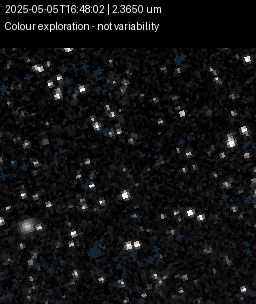

Saved spherex-reproduction\35dd025ce6b077a0\spherex-blink.gif Network preview bytes: 0


In [5]:
run_id=hashlib.sha256(json.dumps(dict(parameters=data['parameters'],source=SOURCE,intent=INTENT,frames=[f['id'] for f in frames]),sort_keys=True).encode()).hexdigest()[:16]
OUTPUT=OUTPUT/run_id;OUTPUT.mkdir(exist_ok=True)
images=[];downloaded=0;asset_hashes=[]
offline_by_id={f['id']:i for i,f in enumerate(data['frames'])}
ordered=sorted(frames,key=lambda f:f['mjd'] if INTENT=='time' else f['wavelength_um'])
for f in ordered:
    if RUN_LIVE:
        assert re.fullmatch(r'/products/[a-f0-9]{24}/(?:raw/)?[0-9]+[.]png',f['image']),'Unexpected image-product path.'
        content=fetch_bytes(f['image'])
        downloaded+=len(content);assert downloaded<=TOTAL_IMAGE_BUDGET
    else: content=(SAMPLE/f"frame-{offline_by_id[f['id']]}.png").read_bytes()
    image=PILImage.open(io.BytesIO(content)).convert('RGB')
    assert not images or image.size==images[0].size,'Different render grids: do not fabricate alignment by resizing.'
    images.append(image);asset_hashes.append(dict(id=f['id'],preview_sha256=hashlib.sha256(content).hexdigest()))
    image.save(OUTPUT/(f['id']+'.png'))
labelled=[]
for f,image in zip(ordered,images):
    canvas=PILImage.new('RGB',(image.width,image.height+48),'black');canvas.paste(image,(0,48))
    draw=ImageDraw.Draw(canvas)
    draw.text((5,3),f"{f['utc'][:19]} | {f['wavelength_um']:.4f} um",fill='white')
    draw.text((5,20),'Time screen only' if INTENT=='time' else 'Colour exploration - not variability',fill='white')
    labelled.append(canvas)
gif=OUTPUT/'spherex-blink.gif'
labelled[0].save(gif,save_all=True,append_images=labelled[1:],duration=700,loop=0)
display(NotebookImage(data=gif.read_bytes(),format='gif'))
print('Saved',gif,'Network preview bytes:',downloaded)

## 5. Export a small evidence package

Includes images, dates, wavelength metadata, response screens, source IDs, recipe and warnings. For exact browser-display reproduction use the shared view URL too: PNG/GIF export does not implement catalogue overlays, browser brightness filters or interactive coadds. No confirmed discovery, calibrated light curve or validated redshift is added.

In [6]:
import csv,zipfile
report=dict(schema_version=2,intent=INTENT,source=SOURCE,job_id=job_id,parameters=data['parameters'],frames=ordered,pair_screens=checks,preview_hashes=asset_hashes,processing=data.get('processing','See per-frame recipe'),warnings=data.get('warnings',[]),saved_view=saved_view,confirmed_discovery=False,limitations=['Prepared previews; no independent WCS/PSF validation.','PNG brightness is not calibrated object photometry.','Frame flags describe cutout metadata, not target detection.','Different wavelengths can mimic change.','GIF does not reproduce overlays or browser display filters.'])
(OUTPUT/'evidence.json').write_text(json.dumps(report,indent=2))
with (OUTPUT/'observations.csv').open('w',newline='') as h:
    writer=csv.DictWriter(h,fieldnames=['id','utc','mjd','wavelength_um','bandwidth_um','detector','collection','source_url'])
    writer.writeheader();writer.writerows({k:f.get(k) for k in writer.fieldnames} for f in ordered)
ZIP_PATH=OUTPUT.parent/f'spherex-evidence-{run_id}.zip'
with zipfile.ZipFile(ZIP_PATH,'w',zipfile.ZIP_DEFLATED) as z:
    for f in OUTPUT.iterdir():
        if f.is_file(): z.write(f,f.name)
print('Saved',ZIP_PATH,'with blink GIF, frame PNGs, observations.csv and evidence.json')

Saved spherex-reproduction\spherex-evidence-35dd025ce6b077a0.zip with blink GIF, frame PNGs, observations.csv and evidence.json


## Credits and next steps

NASA SPHEREx/Science Data Center and NASA/IPAC IRSA supply mission images and archive access. The official [IRSA cutout tutorial](https://caltech-ipac.github.io/irsa-tutorials/spherex-cutouts/) explains native cutout access. Python, NumPy, Pillow and Jupyter support this notebook; original projects retain their licenses. CDS/Gaia/AllWISE catalogue roles are documented in the viewer credits. OpenAI Codex assisted development. This is an independent Space Apps prototype, not NASA/IRSA certification.

Next scientific steps: inspect source identity and neighbourhood, verify registration and comparable responses, model local PSFs and uncertainty, test variability/motion against independent evidence. The separate Galaxy Evidence Lab demonstrates conditional measurement review; it does not supply validated redshifts.